# EDA

- [Introducción a la competición](#Titanic---Machine-Learning-from-Disaster)
- [Descripción del dataset](#Descripción-del-dataset)
- [Importar librerías](#Importar-librerías)
- [Lectura de datos](#Lectura-de-datos)
- [EDA](#Exploratory-Data-Analysis)
    - [Hipótesis previas](#Hipótesis-previas)
    - [Exploración](#Exporación-del-dataset)
    - [Análisis univariable](#Análisis-Univariable)
        - [Estadísticas descriptivas](#Estadísticas-descriptivas) 
        - [Visualizaciones](#Visualizaciones)
    - [Análisis multivariable](#Análisis-Multivariable)
    - [Testeo de hipótesis](#Testeo-Hipótesis)
- [Conclusiones](#Conclusiones)

## Titanic - Machine Learning from Disaster
El hundimiento del Titanic es uno de los naufragios más infames de la historia.

El 15 de abril de 1912, durante su viaje inaugural, el ampliamente considerado "insumergible" RMS Titanic se hundió tras chocar con un iceberg. Desafortunadamente, no había suficientes botes salvavidas para todos a bordo, lo que resultó en la muerte de 1502 de los 2224 pasajeros y tripulantes.

Si bien hubo un elemento de suerte en la supervivencia, parece que algunos grupos de personas tenían más probabilidades de sobrevivir que otros.

En este desafío, te pedimos que construyas un modelo predictivo que responda a la pregunta: "¿qué tipo de personas tenían más probabilidades de sobrevivir?" utilizando los datos de los pasajeros (es decir, nombre, edad, género, clase socioeconómica, etc.).

[Enlace a la competición en kaggle](https://www.kaggle.com/competitions/titanic)

## Descripción del dataset

Los datos se han dividido en dos grupos:

- Conjunto de entrenamiento (train.csv)
- Conjunto de prueba (test.csv)

El **conjunto de entrenamiento** debe utilizarse para construir tus modelos de machine learning. Para el conjunto de entrenamiento, proporcionamos el resultado (también conocido como "ground truth") para cada pasajero. Tu modelo se basará en "características" como el género y la clase de los pasajeros. También puedes usar ingeniería de características para crear nuevas variables.

El **conjunto de prueba** debe utilizarse para evaluar qué tan bien se desempeña tu modelo con datos no vistos. Para el conjunto de prueba, no proporcionamos la verdad real para cada pasajero. Es tu tarea predecir estos resultados. Para cada pasajero en el conjunto de prueba, utiliza el modelo que entrenaste para predecir si sobrevivió o no al hundimiento del Titanic.

### Diccionario de Datos

| **Variable** | **Definición**                                  | **Clave**                                      |
|:------------:|:-----------------------------------------------:|:----------------------------------------------:|
| survival     | Supervivencia                                   | `0 = No, 1 = Sí`                               |
| pclass       | Clase del boleto                                | `1 = 1ra, 2 = 2da, 3 = 3ra`                    |
| sex          | Sexo                                            |                                                |
| age          | Edad en años                                    |                                                |
| sibsp        | Número de hermanos/cónyuges a bordo del Titanic |                                                |
| parch        | Número de padres/hijos a bordo del Titanic      |                                                |
| ticket       | Número de boleto                                |                                                |
| fare         | Tarifa del pasajero                             |                                                |
| cabin        | Número de cabina                                |                                                |
| embarked     | Puerto de embarque                              | `C = Cherburgo, Q = Queenstown, S = Southampton` |


### Notas sobre las Variables

- **pclass**: Un indicador del estatus socioeconómico (SES)

    - 1ra = Upper

    - 2da = Middle

    - 3ra = Lower
      
- **age**: La edad es fraccionada si es menor a 1. Si la edad es estimada, aparece en la forma xx.5
  
- **sibsp**: El conjunto de datos define las relaciones familiares de esta manera...
  
    - Sibling = brother, sister, stepbrother, stepsister
  
    - Spouse = husband, wife (se ignoraron amantes y prometidos)
  
- **parch**: El conjunto de datos define las relaciones familiares de esta manera...
  
    - Parent = mother, father

    - Child = daughter, son, stepdaughter, stepson

Algunos niños viajaban solo con una niñera, por lo tanto, parch=0 para ellos.

## Importar librerías

In [4]:
# Entorno de la asignatura: proyecto_ml (kernel "Python (proyecto_ml)").
# Ya incluye todas las librerías de este notebook: no hace falta instalar nada.

In [5]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, ttest_ind

## Lectura de datos

In [6]:
INPUT_ZIP = "./00_Data/Raw/titanic.zip"  # Directorio del zip
OUTPUT_FOLDER = "./00_Data/Raw"  # Directorio de destino
TRAIN_FILENAME = "train.csv"  # Nombre del fichero de entrenamiento

def fetch_data(input_path=INPUT_ZIP, output_dir=OUTPUT_FOLDER):
    """
    Extrae el contenido de un archivo ZIP en un directorio de destino.

    Parámetros:
    -----------
    input_path : str, opcional
        Ruta al archivo ZIP que se desea descomprimir. El valor predeterminado es la variable 'INPUT_ZIP'.
        
    output_dir : str, opcional
        Directorio en el cual se extraerá el contenido del archivo ZIP. Si el directorio no existe,
        será creado automáticamente. El valor predeterminado es la variable 'OUTPUT_FOLDER'.

    Comportamiento:
    ---------------
    - Crea el directorio de destino si no existe.
    - Descomprime el archivo ZIP en el directorio de destino.

    Excepciones:
    ------------
    Puede lanzar una excepción si el archivo ZIP no existe o si hay problemas al descomprimirlo.

    Ejemplo de uso:
    ---------------
    fetch_data('data.zip', 'output/')
    """
    # Comprobación de que el directorio de destino existe
    os.makedirs(output_dir, exist_ok=True)

    # Descomprime el archivo ZIP en caso de que no haya ningún csv en la carpeta
    if(len([file for file in os.listdir(output_dir) if file.endswith('.csv')]) == 0):
        with zipfile.ZipFile(input_path, 'r') as zip_ref:
            zip_ref.extractall(output_dir)


def load_data(directory=OUTPUT_FOLDER, filename=TRAIN_FILENAME):
    """
    Lee un archivo CSV desde el directorio especificado.

    Parámetros:
    -----------
    directory : str
        El directorio donde se encuentra el archivo CSV.
        
    filename : str
        El nombre del archivo CSV a leer (incluyendo la extensión .csv).

    Retorna:
    --------
    pd.DataFrame
        Un DataFrame de pandas que contiene los datos del archivo CSV.

    Excepciones:
    ------------
    FileNotFoundError:
        Se lanza si el archivo no existe en el directorio dado.
    
    Ejemplo de uso:
    ---------------
    df = read_csv_from_directory('data', 'file.csv')
    """
    # Construir la ruta completa al archivo CSV
    file_path = os.path.join(directory, filename)

    # Verificar si el archivo existe
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"El archivo {filename} no se encuentra en el directorio {directory}")

    # Leer el archivo CSV en un DataFrame
    return pd.read_csv(file_path)

fetch_data()
df = load_data()
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## Hipótesis previas

1. **Hipótesis de Género**: Las mujeres tuvieron una mayor probabilidad de sobrevivir que los hombres debido al protocolo de evacuación de "mujeres y niños primero".

2. **Hipótesis de Clase**: Los pasajeros de clases más altas (`Pclass = 1`) tuvieron una mayor probabilidad de sobrevivir en comparación con los pasajeros de clases más bajas, reflejando las desigualdades sociales de la época.

3. **Hipótesis de Edad**: Los pasajeros más jóvenes (niños) tuvieron una mayor probabilidad de sobrevivir debido a que se les dio prioridad en los esfuerzos de rescate.

4. **Hipótesis de Tamaño de la Familia**: Los pasajeros que viajaban con familia tuvieron mayores probabilidades de sobrevivir en comparación con aquellos que viajaban solos. Sin embargo, familias muy grandes pudieron tener dificultades para escapar juntas, reduciendo sus posibilidades de supervivencia.

5. **Hipótesis de la Tarifa**: Los pasajeros que pagaron tarifas más altas tuvieron una mayor probabilidad de sobrevivir, ya que es probable que estuvieran en camarotes de clases superiores y tuvieran mejor acceso a los botes salvavidas.

6. **Hipótesis del Punto de Embarque**: Los pasajeros que embarcaron en ciertos puntos, como Cherburgo (`Embarked = C`), tuvieron mayores probabilidades de sobrevivir debido a diferencias en riqueza o ubicación de los camarotes.

7. **Hipótesis de Disponibilidad de Cabina**: Los pasajeros con información de cabina disponible (`Cabin` no nulo) tuvieron una mayor probabilidad de sobrevivir, ya que probablemente estaban en las secciones de clase alta del barco.

8. **Hipótesis de Título**: Los pasajeros con ciertos títulos, como `Mrs`, `Miss` o `Master` (niños), tuvieron mejores probabilidades de sobrevivir que otros, reflejando su estatus social o edad.

9. **Hipótesis del Número de Ticket**: Los pasajeros con números de ticket similares, lo que podría indicar que viajaban juntos, tuvieron probabilidades de supervivencia correlacionadas.

10. **Hipótesis de Interacciones**:
    - **Género y Clase**: Las mujeres de clases más altas tuvieron la mayor tasa de supervivencia.
    - **Edad y Clase**: Los niños de clases más bajas tuvieron menos probabilidades de sobrevivir que los niños de clases más altas.
    - **Tamaño de Familia y Tarifa**: Los pasajeros con familias más pequeñas y tarifas más altas tuvieron mayores probabilidades de supervivencia.

## Exploratory Data Analysis

### Exporación del dataset

In [7]:
df.shape

(891, 12)

In [8]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [11]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

#### Comentarios:
- Existen missing values en 'Age', 'Cabin' y 'Embarked' con los que tendremos que tratar.
- Los tipos de las variables parecen correctos, aunque 'Age' debería ser entero y aparece como float --> posiblemente por los NaNs
- La columna 'Name' no aporta mucho por sí misma, veremos si podemos extraer algo de ésta que sí valga.

### Análisis Univariable

#### Estadísticas descriptivas

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [13]:
# Calcular moda
df.mode().T

,0,1,2,3,4,5,6,7,8,9,...,881,882,883,884,885,886,887,888,889,890
PassengerId,1,2,3,4,5,6,7,8,9,10,...,882,883,884,885,886,887,888,889,890,891
Survived,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pclass,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,"Abbing, Mr. Anthony","Abbott, Mr. Rossmore Edward","Abbott, Mrs. Stanton (Rosa Hunt)","Abelson, Mr. Samuel","Abelson, Mrs. Samuel (Hannah Wizosky)","Adahl, Mr. Mauritz Nils Martin","Adams, Mr. John","Ahlin, Mrs. Johan (Johanna Persdotter Larsson)","Aks, Mrs. Sam (Leah Rosen)","Albimona, Mr. Nassef Cassem",...,"Yrois, Miss. Henriette (""Mrs Harbeck"")","Zabour, Miss. Hileni","Zabour, Miss. Thamine","Zimmerman, Mr. Leo","de Messemaeker, Mrs. Guillaume Joseph (Emma)","de Mulder, Mr. Theodore","de Pelsmaeker, Mr. Alfons","del Carlo, Mr. Sebastiano","van Billiard, Mr. Austin Blyler","van Melkebeke, Mr. Philemon"
Sex,male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,24.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SibSp,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Parch,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket,1601,347082,CA. 2343,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,8.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# Calcular moda (elimino 'Name' & 'PassengerID' para eliminar múltiples columnas)
df.drop(columns=["Name", "PassengerId"]).mode().T

,0,1,2
Survived,0.0,NaN,NaN
Pclass,3.0,NaN,NaN
Sex,male,NaN,NaN
Age,24.0,NaN,NaN
SibSp,0.0,NaN,NaN
Parch,0.0,NaN,NaN
Ticket,1601,347082,CA. 2343
Fare,8.05,NaN,NaN
Cabin,B96 B98,C23 C25 C27,G6
Embarked,S,NaN,NaN


In [15]:
# Calcular IQR
df.describe().T["75%"] - df.describe().T["25%"]

PassengerId    445.0000
Survived         1.0000
Pclass           1.0000
Age             17.8750
SibSp            1.0000
Parch            0.0000
Fare            23.0896
dtype: float64

In [16]:
# Calcular rango
df.describe().T["max"] - df.describe().T["min"]

PassengerId    890.0000
Survived         1.0000
Pclass           2.0000
Age             79.5800
SibSp            8.0000
Parch            6.0000
Fare           512.3292
dtype: float64

In [17]:
# Almacenar columnas numéricas para evitar error
num_columns = df.describe().columns
num_columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='str')

In [18]:
# Calcular asimetría
"""
valor > 0 -> distribución asimétrica a la derecha
valor = 0 -> distribución simétrica
valor < 0 -> distribución asimétrica a la izquierda
"""
df[num_columns].skew()

PassengerId    0.000000
Survived       0.478523
Pclass        -0.630548
Age            0.389108
SibSp          3.695352
Parch          2.749117
Fare           4.787317
dtype: float64

In [19]:
# Calcular la curtosis
"""
valor > 0 -> distribución leptocúrtica
valor = 0 -> distribución mesocúrtica
valor < 0 -> distribución platicúrtica
"""
df[num_columns].kurt()

PassengerId    -1.200000
Survived       -1.775005
Pclass         -1.280015
Age             0.178274
SibSp          17.880420
Parch           9.778125
Fare           33.398141
dtype: float64

#### Visualizaciones

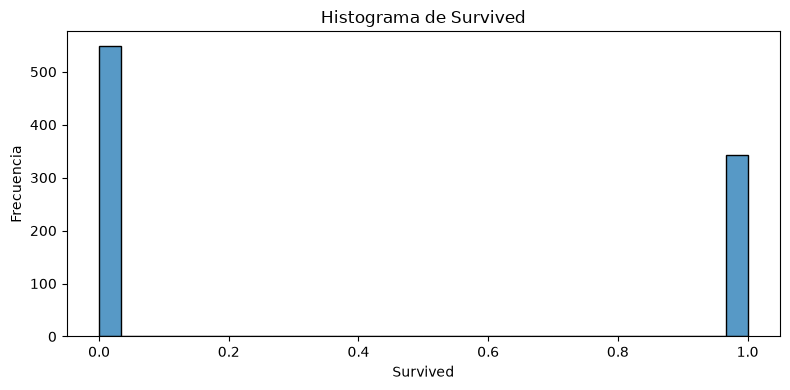

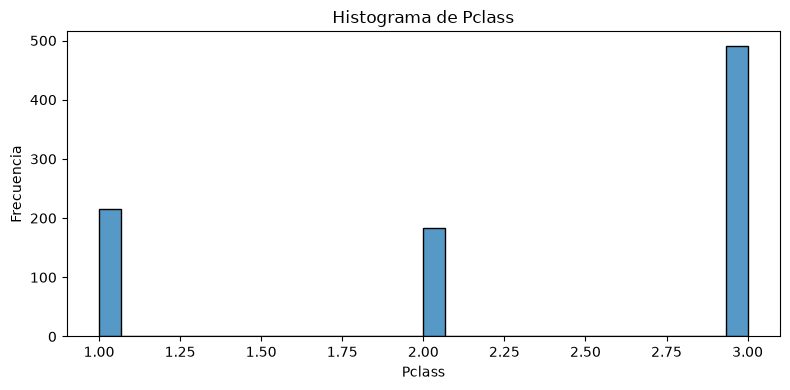

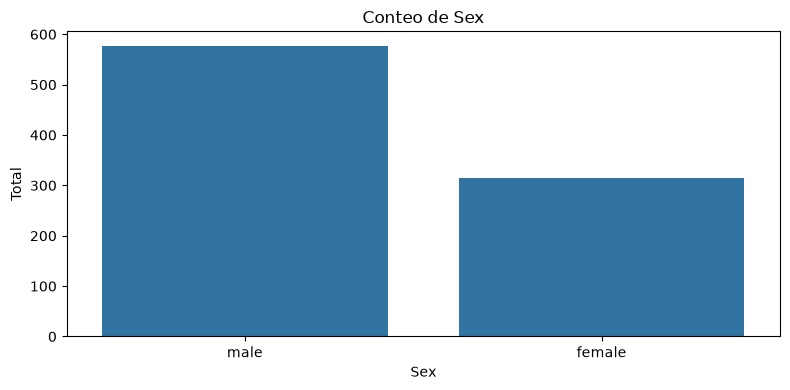

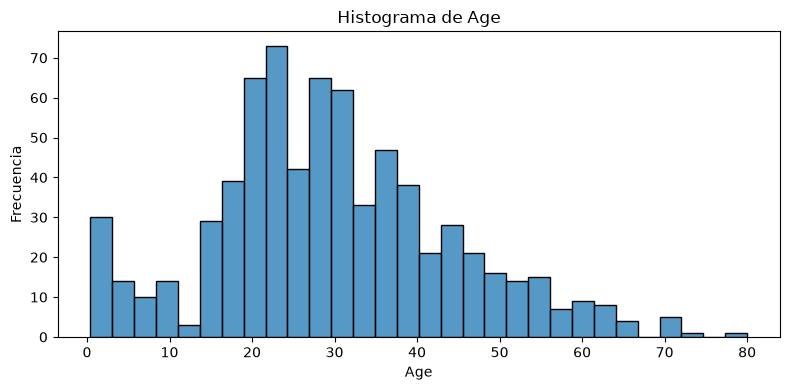

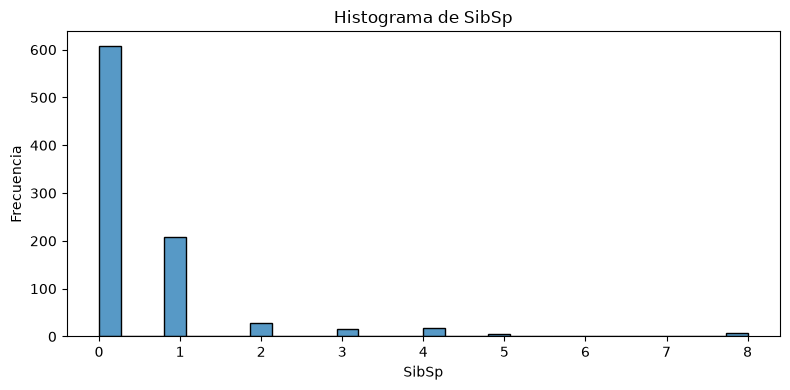

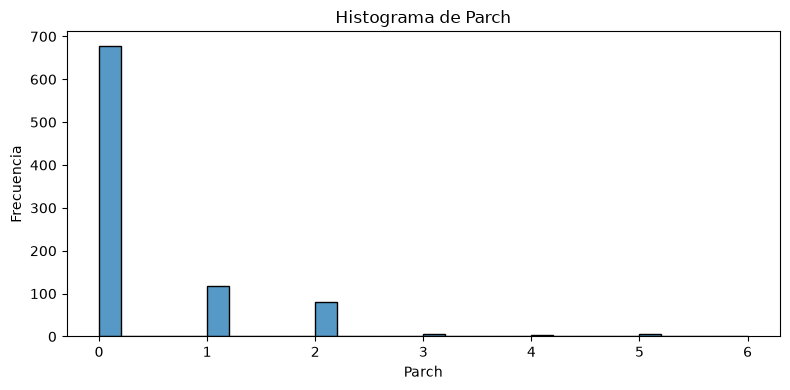

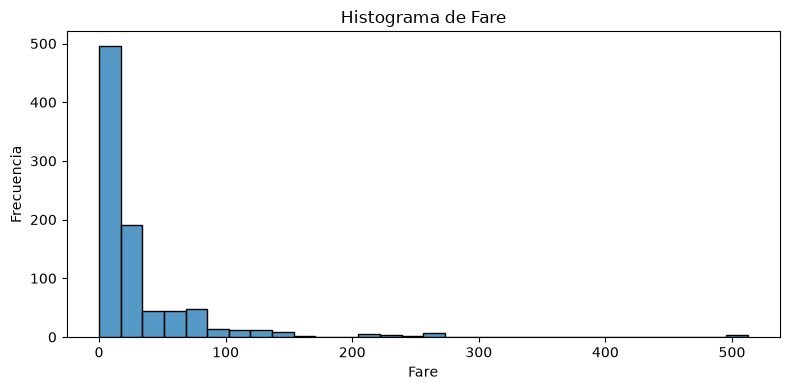

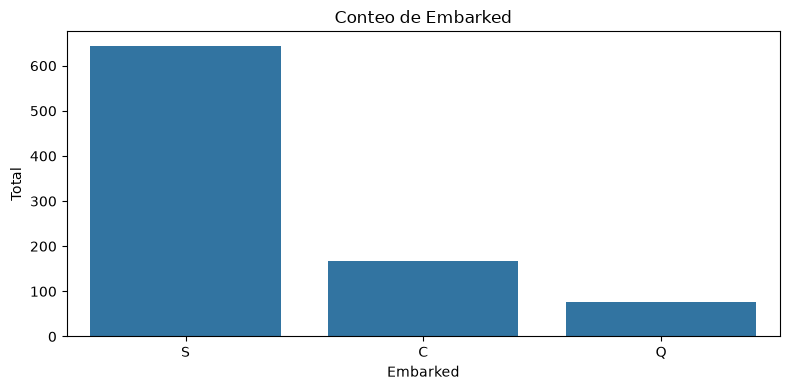

In [20]:
# Pintamos solo las variables con sentido (excluimos identificadores y texto libre)
cols_plot = [c for c in df.columns if c not in ['PassengerId', 'Name', 'Ticket', 'Cabin']]
for column in cols_plot:
    plt.figure(figsize=(8, 4))
    if pd.api.types.is_numeric_dtype(df[column]):
        sns.histplot(df[column].dropna(), bins=30)
        plt.title(f'Histograma de {column}')
        plt.ylabel('Frecuencia')
    else:
        sns.countplot(x=df[column])
        plt.title(f'Conteo de {column}')
        plt.ylabel('Total')
    plt.tight_layout()
    plt.show()

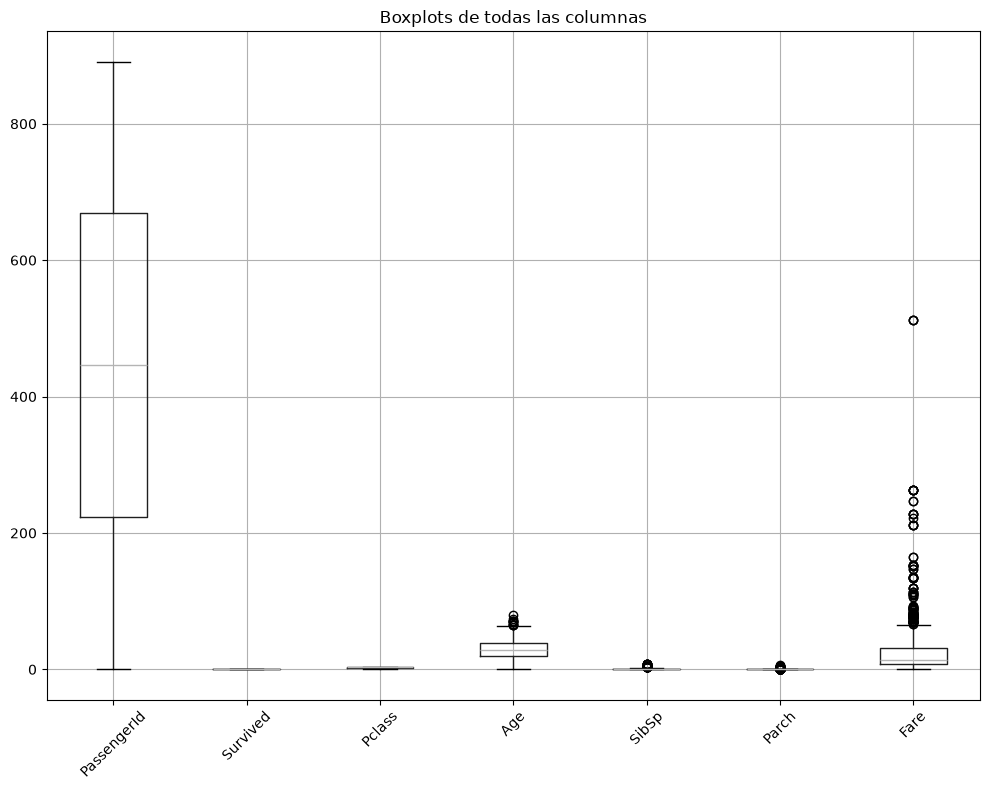

In [21]:
# Genera boxplots para cada columna numérica del DataFrame
df.boxplot(figsize=(10, 8), rot=45)
plt.title('Boxplots de todas las columnas')
plt.tight_layout()  # Para ajustar mejor el espacio de la gráfica
plt.show()

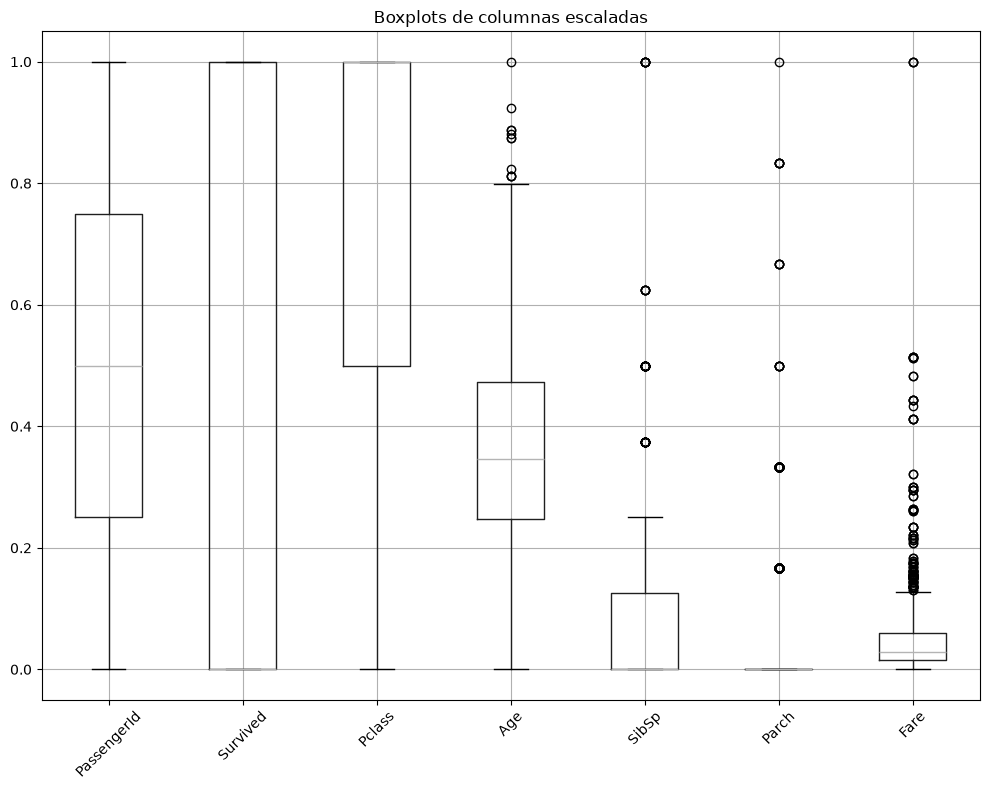

In [22]:
from sklearn.preprocessing import MinMaxScaler

# Seleccionamos solo las columnas numéricas
numeric_columns = df.select_dtypes(include=['float', 'int']).columns
df_numeric = df[numeric_columns]

# Normalizamos los datos entre 0 y 1
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_numeric), columns=numeric_columns)

# Genera boxplots para las columnas escaladas
df_scaled.boxplot(figsize=(10, 8), rot=45)
plt.title('Boxplots de columnas escaladas')
plt.tight_layout()
plt.show()

#### Comentarios:
Los valores parecen ser coherentes.

### Análisis Multivariable

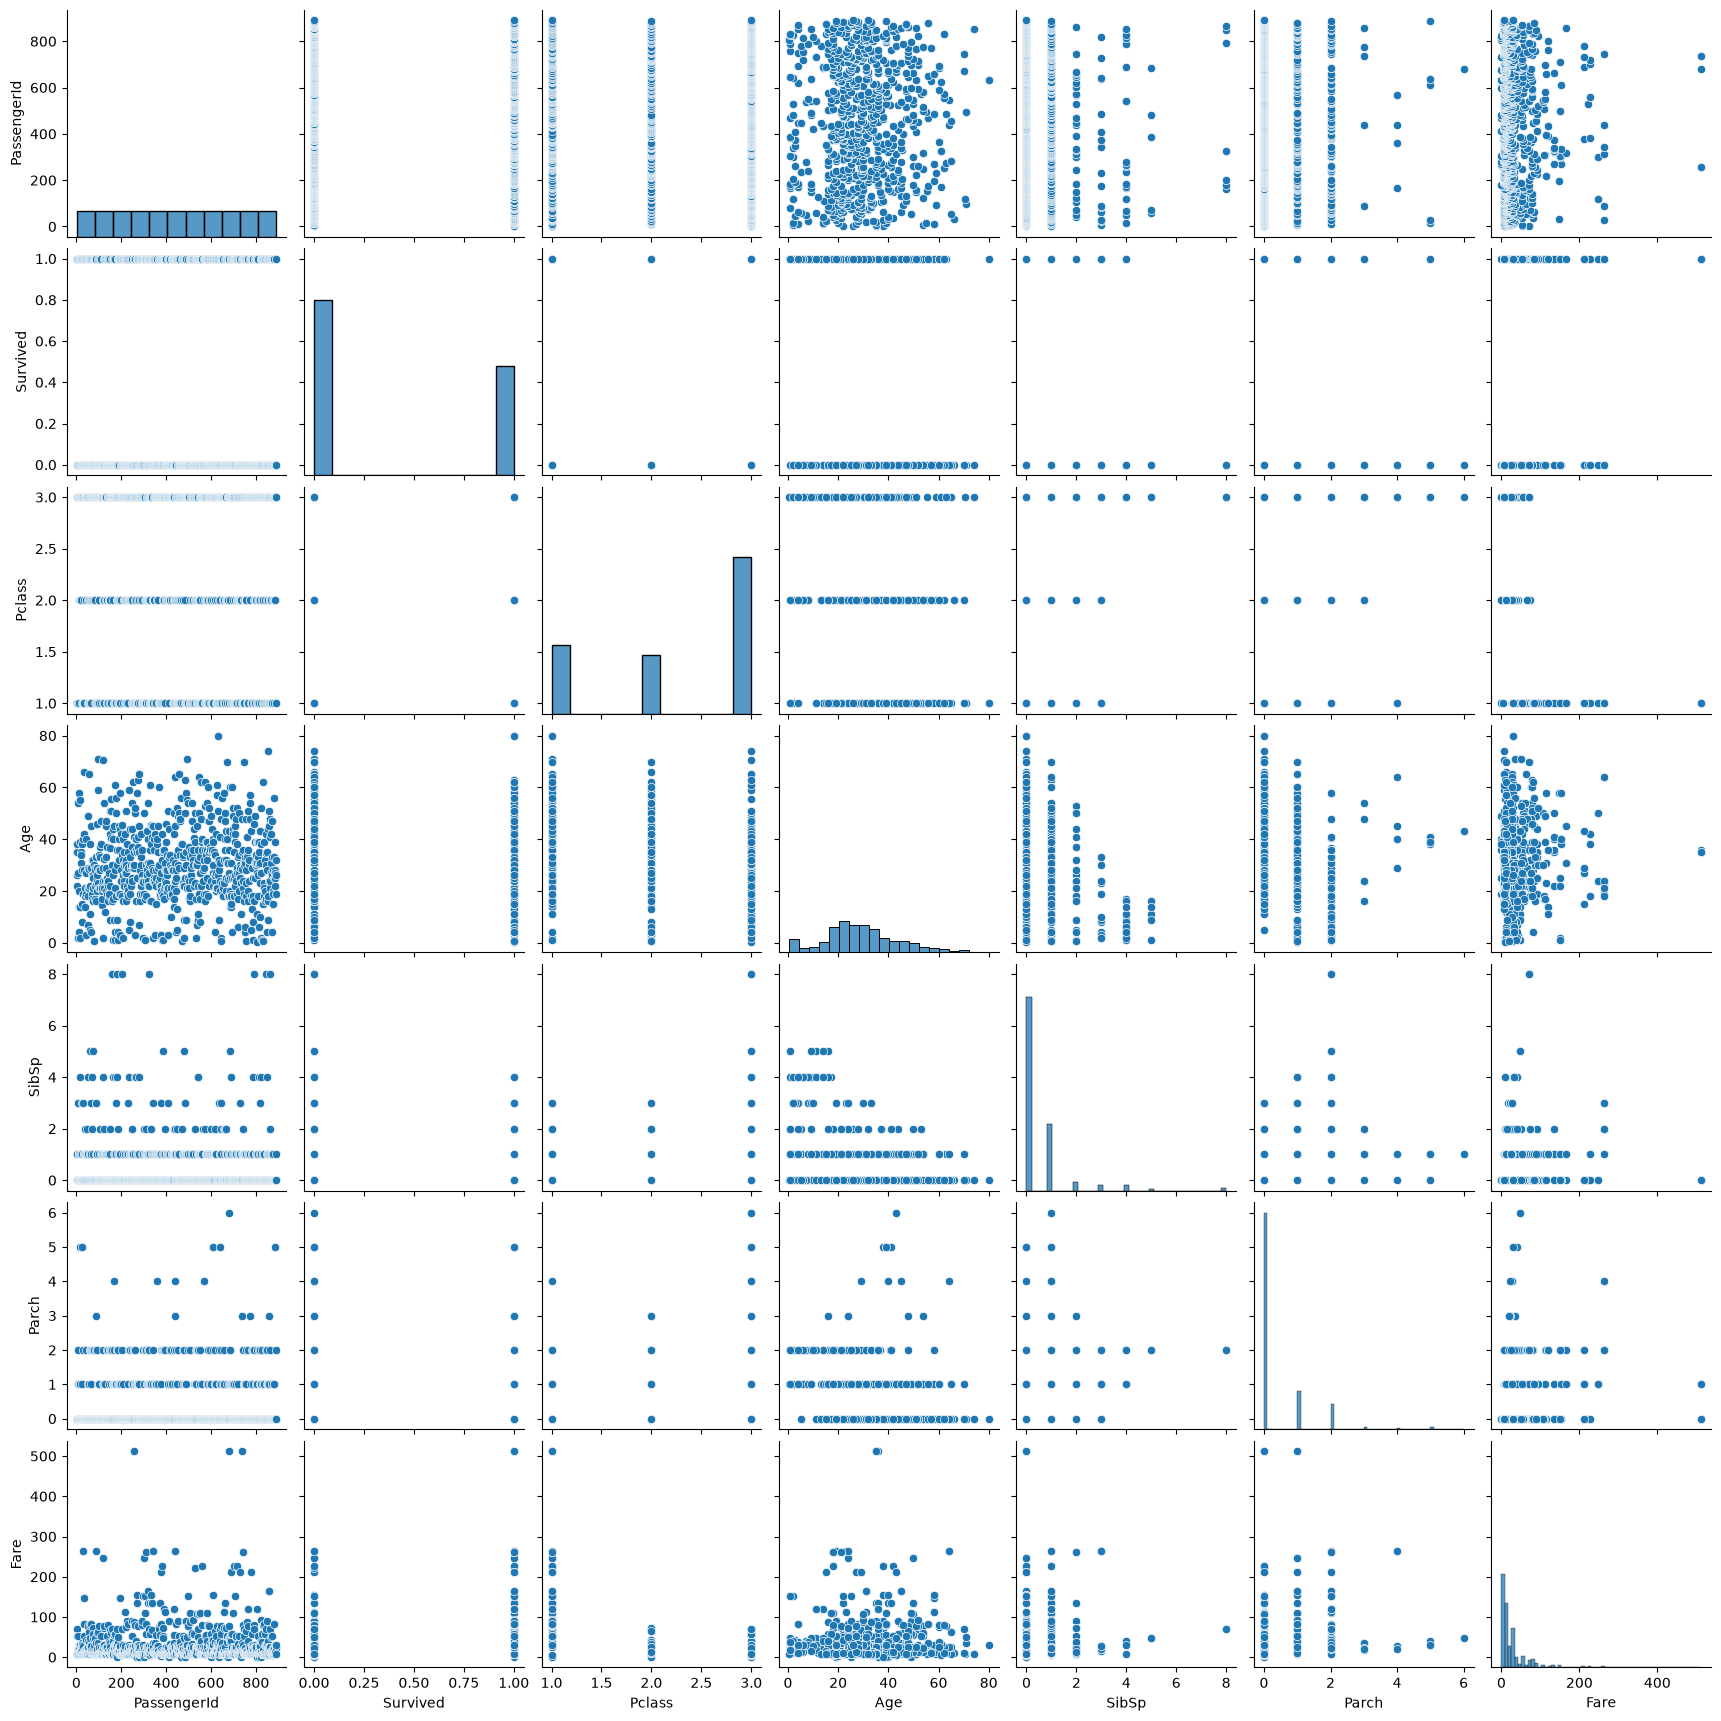

In [23]:
sns.pairplot(df);

In [24]:
# Correlaciones
df[num_columns].corr()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


In [25]:
# Defino un cmap para ver más claramente los colores
cmap = sns.diverging_palette(500, 10, as_cmap=True)

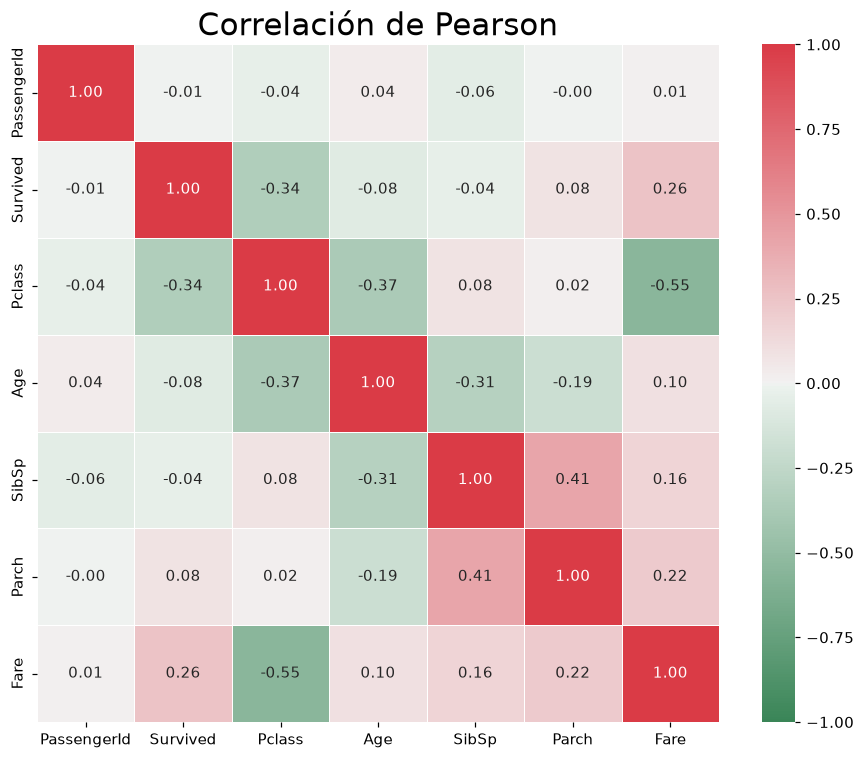

In [26]:
plt.figure(figsize=(10,8), dpi=110)
sns.heatmap(df[num_columns].corr(method='pearson'),
            annot=True, 
            fmt=".2f", linewidth=.5, cmap=cmap, vmin=-1, vmax=1)
plt.title("Correlación de Pearson", fontsize =20)
plt.show()

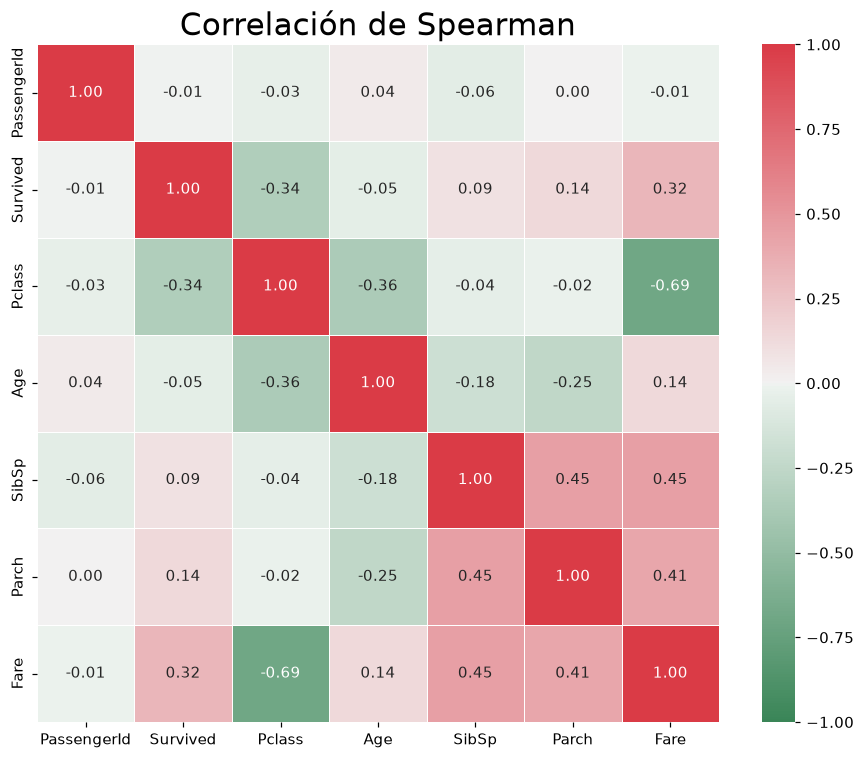

In [27]:
plt.figure(figsize=(10,8), dpi=110)
sns.heatmap(df[num_columns].corr(method='spearman'),
            annot=True, 
            fmt=".2f", linewidth=.5, cmap=cmap, vmin=-1, vmax=1)
plt.title("Correlación de Spearman", fontsize =20)
plt.show()

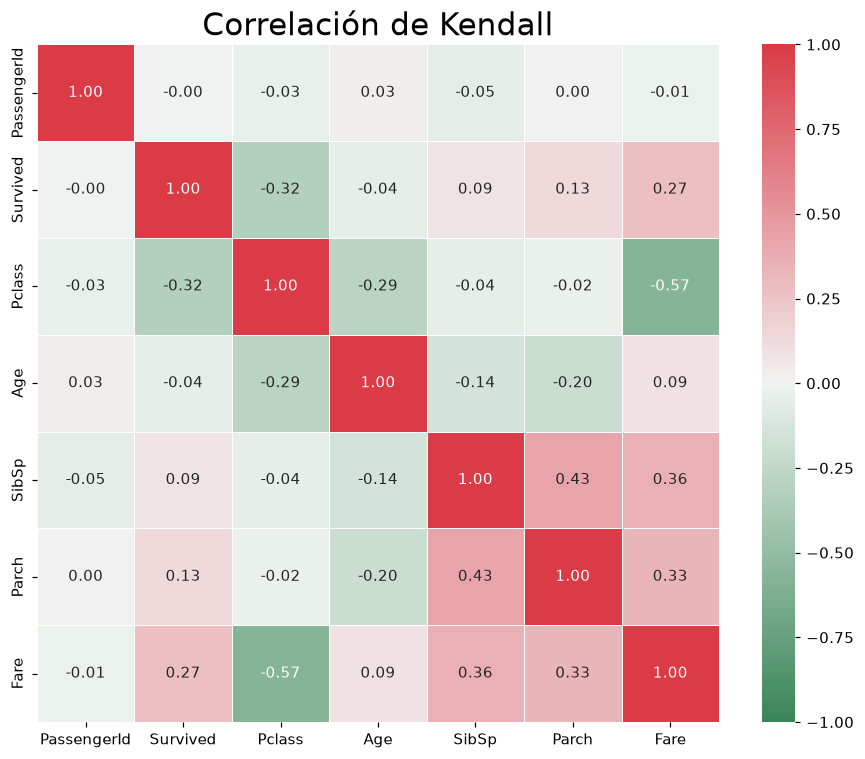

In [28]:
plt.figure(figsize=(10,8), dpi=110)
sns.heatmap(df[num_columns].corr(method='kendall'),
            annot=True, 
            fmt=".2f", linewidth=.5, cmap=cmap, vmin=-1, vmax=1)
plt.title("Correlación de Kendall", fontsize =20)
plt.show()

#### Comentarios:
No parece que haya correlaciones demasiado fuertes entre variables, salvo la trivial (clase-tarifa)

### Testeo Hipótesis

> **Cómo testear cada hipótesis (guía):** para cada una, apóyate en un **gráfico** (p. ej. `pd.crosstab(..., normalize='index').plot(kind='bar', stacked=True)` o un `groupby('...')['Survived'].mean()`) y confírmalo con una **prueba estadística**:
> - Variables **categóricas** (Sex, Pclass, Embarked, Has_Cabin, Title…): **chi²** con `scipy.stats.chi2_contingency` sobre `pd.crosstab(var, Survived)`.
> - Variables **numéricas** (Age, Fare…): **t-test** con `scipy.stats.ttest_ind` comparando supervivientes vs no supervivientes.
>
> Interpreta el p-valor: si **p < 0.05**, la relación/diferencia es estadísticamente significativa.

1. **Hipótesis de Género**: Las mujeres tuvieron una mayor probabilidad de sobrevivir que los hombres debido al protocolo de evacuación de "mujeres y niños primero".

Survived,0,1
Sex,,
female,81,233
male,468,109


,Pasajeros,Supervivientes,Tasa_supervivencia
Sex,,,
female,314,233,74.20
male,577,109,18.89


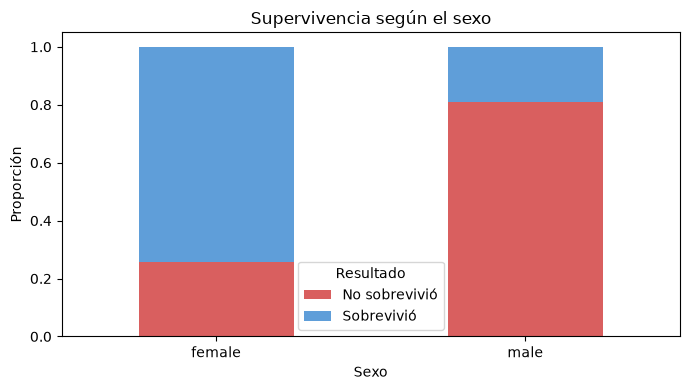

Chi-cuadrado: 260.72
P-valor: 1.1974e-58
Existe una relación estadísticamente significativa entre el sexo y la supervivencia.


In [142]:
# Tabla con el número de supervivientes y fallecidos según el sexo
tabla_genero = pd.crosstab(df["Sex"], df["Survived"])
display(tabla_genero)

# Tasas de supervivencia
tasas_genero = (
    df.groupby("Sex")["Survived"]
      .agg(Pasajeros="count", Supervivientes="sum", Tasa_supervivencia="mean")
)

tasas_genero["Tasa_supervivencia"] *= 100
display(tasas_genero.round(2))

# Gráfico
pd.crosstab(
    df["Sex"],
    df["Survived"],
    normalize="index"
).plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4),
    color=["#d95f5f", "#5f9ed9"]
)

plt.title("Supervivencia según el sexo")
plt.xlabel("Sexo")
plt.ylabel("Proporción")
plt.xticks(rotation=0)
plt.legend(["No sobrevivió", "Sobrevivió"], title="Resultado")
plt.tight_layout()
plt.show()

# Prueba chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = chi2_contingency(
    tabla_genero
)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("Existe una relación estadísticamente significativa entre el sexo y la supervivencia.")
else:
    print("No se ha encontrado una relación estadísticamente significativa.")

Conclusión: Las mujeres presentaron una tasa de supervivencia del 74,20 %, frente al 18,89 % de los hombres. La prueba chi-cuadrado produjo un p-valor inferior a 0,05, por lo que existe una relación estadísticamente significativa entre el sexo y la supervivencia. Los datos apoyan la hipótesis de que las mujeres tuvieron una mayor probabilidad de sobrevivir. Este análisis demuestra una asociación, pero no permite atribuirla por sí solo al protocolo de evacuación.

2. **Hipótesis de Clase**: Los pasajeros de clases más altas (`Pclass = 1`) tuvieron una mayor probabilidad de sobrevivir en comparación con los pasajeros de clases más bajas, reflejando las desigualdades sociales de la época.

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


,Pasajeros,Supervivientes,Tasa_supervivencia
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


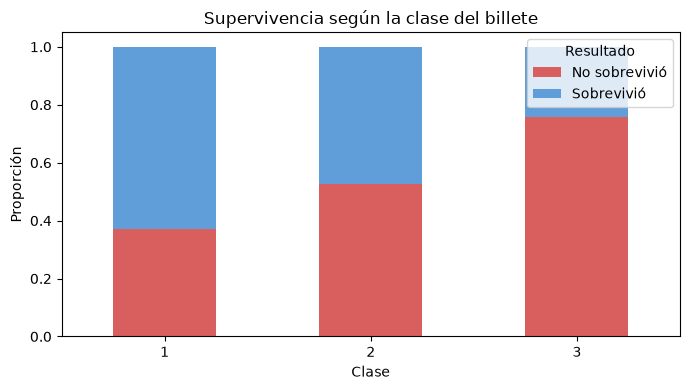

Chi-cuadrado: 102.89
P-valor: 4.5493e-23
Existe una relación estadísticamente significativa entre la clase y la supervivencia.


In [143]:
# Tabla de supervivencia según la clase del billete
tabla_clase = pd.crosstab(df["Pclass"], df["Survived"])
display(tabla_clase)

# Tasas de supervivencia por clase
tasas_clase = (
    df.groupby("Pclass")["Survived"]
      .agg(Pasajeros="count", Supervivientes="sum", Tasa_supervivencia="mean")
)

tasas_clase["Tasa_supervivencia"] *= 100
display(tasas_clase.round(2))

# Gráfico
pd.crosstab(
    df["Pclass"],
    df["Survived"],
    normalize="index"
).plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4),
    color=["#d95f5f", "#5f9ed9"]
)

plt.title("Supervivencia según la clase del billete")
plt.xlabel("Clase")
plt.ylabel("Proporción")
plt.xticks(rotation=0)
plt.legend(["No sobrevivió", "Sobrevivió"], title="Resultado")
plt.tight_layout()
plt.show()

# Prueba chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = chi2_contingency(
    tabla_clase
)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("Existe una relación estadísticamente significativa entre la clase y la supervivencia.")
else:
    print("No se ha encontrado una relación estadísticamente significativa.")

Conclusión:La tasa de supervivencia fue del 62,96 % en primera clase, del 47,28 % en segunda clase y del 24,24 % en tercera clase. La prueba chi-cuadrado produjo un p-valor inferior a 0,05, por lo que existe una relación estadísticamente significativa entre la clase del billete y la supervivencia. Los datos apoyan la hipótesis de que los pasajeros de las clases más altas tuvieron una mayor probabilidad de sobrevivir. El análisis muestra una asociación, pero no demuestra por sí solo que la clase fuese la causa directa.

3. **Hipótesis de Edad**: Los pasajeros más jóvenes (niños) tuvieron una mayor probabilidad de sobrevivir debido a que se les dio prioridad en los esfuerzos de rescate.

,Pasajeros,Supervivientes,Tasa_supervivencia
Grupo_edad,,,
Adulto,601,229,38.10
Menor de 18,113,61,53.98


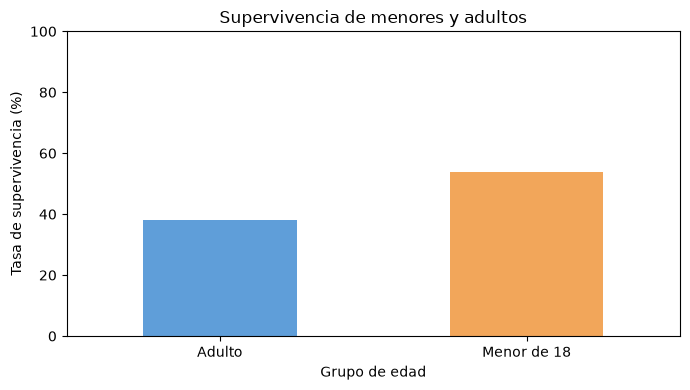

Edad media de los supervivientes: 28.34
Edad media de los no supervivientes: 30.63
Estadístico t: -2.05
P-valor: 0.0412
La diferencia de edad es estadísticamente significativa.


In [144]:
# Eliminamos únicamente las filas cuya edad es desconocida
df_edad = df.dropna(subset=["Age"]).copy()

# Creamos dos grupos: menores de 18 años y adultos
df_edad["Grupo_edad"] = np.where(
    df_edad["Age"] < 18,
    "Menor de 18",
    "Adulto"
)

# Tasas de supervivencia por grupo
tasas_edad = (
    df_edad.groupby("Grupo_edad")["Survived"]
           .agg(Pasajeros="count",
                Supervivientes="sum",
                Tasa_supervivencia="mean")
)

tasas_edad["Tasa_supervivencia"] *= 100
display(tasas_edad.round(2))

# Gráfico
tasas_edad["Tasa_supervivencia"].plot(
    kind="bar",
    figsize=(7, 4),
    color=["#5f9ed9", "#f2a65a"]
)

plt.title("Supervivencia de menores y adultos")
plt.xlabel("Grupo de edad")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Edades de supervivientes y no supervivientes
edad_supervivientes = df_edad.loc[
    df_edad["Survived"] == 1, "Age"
]

edad_no_supervivientes = df_edad.loc[
    df_edad["Survived"] == 0, "Age"
]

print(f"Edad media de los supervivientes: {edad_supervivientes.mean():.2f}")
print(f"Edad media de los no supervivientes: {edad_no_supervivientes.mean():.2f}")

# T-test de Welch
t_stat, p_valor = ttest_ind(
    edad_supervivientes,
    edad_no_supervivientes,
    equal_var=False
)

print(f"Estadístico t: {t_stat:.2f}")
print(f"P-valor: {p_valor:.4f}")

if p_valor < 0.05:
    print("La diferencia de edad es estadísticamente significativa.")
else:
    print("La diferencia de edad no es estadísticamente significativa.")

Conclusión: Los menores de 18 años tuvieron una tasa de supervivencia del 53,98 %, frente al 38,10 % de los adultos. Además, la edad media de los supervivientes fue de 28,34 años y la de los no supervivientes fue de 30,63 años. El t-test produjo un p-valor de 0,0412, inferior a 0,05, por lo que la diferencia es estadísticamente significativa. Los resultados apoyan la hipótesis de que los pasajeros más jóvenes tuvieron una mayor probabilidad de sobrevivir. El análisis solo incluye a los 714 pasajeros cuya edad está registrada.

4. **Hipótesis de Tamaño de la Familia**: Los pasajeros que viajaban con familia tuvieron mayores probabilidades de sobrevivir en comparación con aquellos que viajaban solos. Sin embargo, familias muy grandes pudieron tener dificultades para escapar juntas, reduciendo sus posibilidades de supervivencia.

,Pasajeros,Supervivientes,Tasa_supervivencia
Grupo_familia,,,
Solo,537,163,30.35
Familia de 2 a 4,292,169,57.88
Familia de 5 o más,62,10,16.13


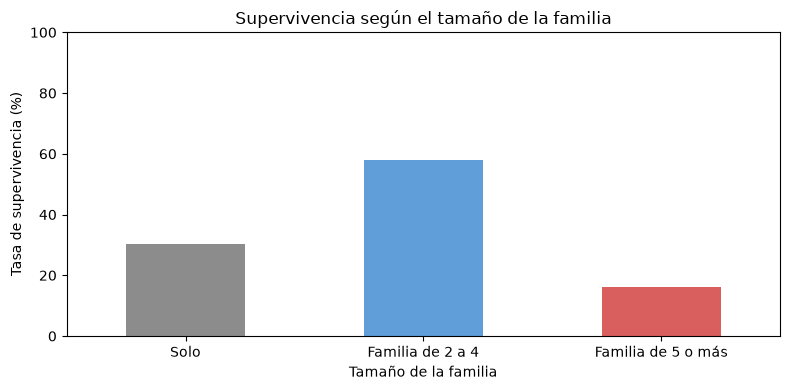

Survived,0,1
Grupo_familia,,
Solo,374,163
Familia de 2 a 4,123,169
Familia de 5 o más,52,10


Chi-cuadrado: 74.54
P-valor: 6.5229e-17
Grados de libertad: 2
Existe una relación estadísticamente significativa entre el tamaño familiar y la supervivencia.


In [145]:
# Creamos una copia para no modificar el DataFrame original
df_familia = df.copy()

# Tamaño total de la familia, incluyendo al propio pasajero
df_familia["FamilySize"] = (
    df_familia["SibSp"] +
    df_familia["Parch"] +
    1
)

# Clasificamos a los pasajeros según el tamaño familiar
df_familia["Grupo_familia"] = pd.cut(
    df_familia["FamilySize"],
    bins=[0, 1, 4, np.inf],
    labels=[
        "Solo",
        "Familia de 2 a 4",
        "Familia de 5 o más"
    ]
)

# Calculamos las tasas de supervivencia
tasas_familia = (
    df_familia.groupby(
        "Grupo_familia",
        observed=False
    )["Survived"]
    .agg(
        Pasajeros="count",
        Supervivientes="sum",
        Tasa_supervivencia="mean"
    )
)

# Convertimos la tasa en porcentaje
tasas_familia["Tasa_supervivencia"] *= 100

display(tasas_familia.round(2))

# Representamos las tasas de supervivencia
tasas_familia["Tasa_supervivencia"].plot(
    kind="bar",
    figsize=(8, 4),
    color=["#8c8c8c", "#5f9ed9", "#d95f5f"]
)

plt.title("Supervivencia según el tamaño de la familia")
plt.xlabel("Tamaño de la familia")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Creamos la tabla de contingencia
tabla_familia = pd.crosstab(
    df_familia["Grupo_familia"],
    df_familia["Survived"]
)

display(tabla_familia)

# Aplicamos la prueba chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = (
    chi2_contingency(tabla_familia)
)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")

if p_valor < 0.05:
    print(
        "Existe una relación estadísticamente significativa "
        "entre el tamaño familiar y la supervivencia."
    )
else:
    print(
        "No se ha encontrado una relación estadísticamente "
        "significativa entre el tamaño familiar y la supervivencia."
    )

Conclusión: Los pasajeros que viajaban solos tuvieron una tasa de supervivencia del 30,35 %. La tasa aumentó hasta el 57,88 % entre quienes viajaban en familias de 2 a 4 personas, mientras que descendió al 16,13 % en las familias de 5 o más. La prueba chi-cuadrado produjo un p-valor de aproximadamente 6,52

5. **Hipótesis de la Tarifa**: Los pasajeros que pagaron tarifas más altas tuvieron una mayor probabilidad de sobrevivir, ya que es probable que estuvieran en camarotes de clases superiores y tuvieran mejor acceso a los botes salvavidas.

,Pasajeros,Media,Mediana
No sobrevivió,549,22.12,10.5
Sobrevivió,342,48.40,26.0


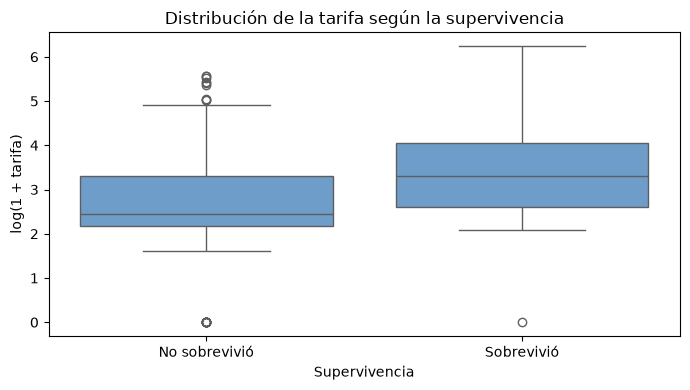

Tarifa media de supervivientes: 48.40
Tarifa media de no supervivientes: 22.12
Estadístico t: 6.84
P-valor: 2.6993e-11
La diferencia de tarifas es estadísticamente significativa.


In [146]:
# Resumen de la tarifa según el resultado de supervivencia
resumen_tarifa = (
    df.groupby("Survived")["Fare"]
      .agg(Pasajeros="count", Media="mean", Mediana="median")
)

resumen_tarifa.index = ["No sobrevivió", "Sobrevivió"]
display(resumen_tarifa.round(2))

# Aplicamos log1p para representar mejor una variable con valores extremos
df_tarifa = df.copy()
df_tarifa["Fare_log"] = np.log1p(df_tarifa["Fare"])

# Gráfico
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df_tarifa,
    x="Survived",
    y="Fare_log",
    color="#5f9ed9"
)

plt.title("Distribución de la tarifa según la supervivencia")
plt.xlabel("Supervivencia")
plt.ylabel("log(1 + tarifa)")
plt.xticks([0, 1], ["No sobrevivió", "Sobrevivió"])
plt.tight_layout()
plt.show()

# Tarifas de ambos grupos
tarifa_supervivientes = df.loc[
    df["Survived"] == 1, "Fare"
].dropna()

tarifa_no_supervivientes = df.loc[
    df["Survived"] == 0, "Fare"
].dropna()

# T-test de Welch
t_stat, p_valor = ttest_ind(
    tarifa_supervivientes,
    tarifa_no_supervivientes,
    equal_var=False
)

print(f"Tarifa media de supervivientes: {tarifa_supervivientes.mean():.2f}")
print(f"Tarifa media de no supervivientes: {tarifa_no_supervivientes.mean():.2f}")
print(f"Estadístico t: {t_stat:.2f}")
print(f"P-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("La diferencia de tarifas es estadísticamente significativa.")
else:
    print("La diferencia de tarifas no es estadísticamente significativa.")

Conclusión: Los supervivientes pagaron una tarifa media de 48,40 y una mediana de 26,00, mientras que los no supervivientes pagaron una media de 22,12 y una mediana de 10,50. El t-test produjo un p-valor inferior a 0,05, por lo que la diferencia de tarifas es estadísticamente significativa. Los datos apoyan la hipótesis de que las tarifas más altas estuvieron asociadas con una mayor probabilidad de sobrevivir. La tarifa también está relacionada con la clase del billete, por lo que este análisis no permite considerarla una causa independiente.

6. **Hipótesis del Punto de Embarque**: Los pasajeros que embarcaron en ciertos puntos, como Cherburgo (`Embarked = C`), tuvieron mayores probabilidades de sobrevivir debido a diferencias en riqueza o ubicación de los camarotes.

,Pasajeros,Supervivientes,Tasa_supervivencia
Puerto,,,
Cherburgo,168,93,55.36
Queenstown,77,30,38.96
Southampton,644,217,33.70


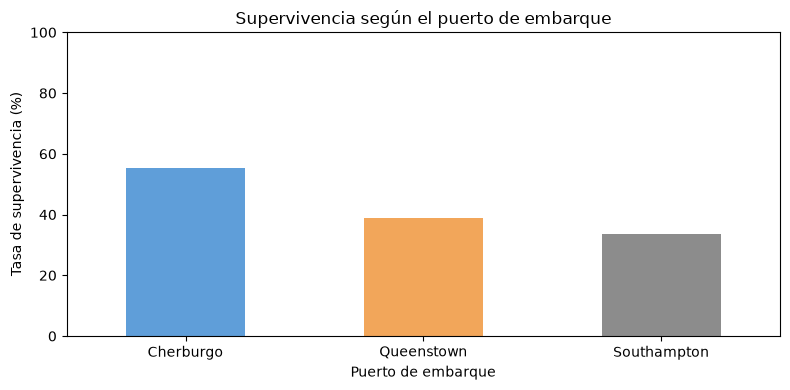

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


Chi-cuadrado: 26.49
P-valor: 1.7699e-06
Grados de libertad: 2
Existe una relación estadísticamente significativa entre el puerto de embarque y la supervivencia.


In [147]:
# Eliminamos únicamente los pasajeros sin puerto de embarque registrado
df_puerto = df.dropna(subset=["Embarked"]).copy()

# Sustituimos los códigos por nombres comprensibles
nombres_puertos = {
    "C": "Cherburgo",
    "Q": "Queenstown",
    "S": "Southampton"
}

df_puerto["Puerto"] = df_puerto["Embarked"].map(nombres_puertos)

# Calculamos las tasas de supervivencia
tasas_puerto = (
    df_puerto.groupby("Puerto")["Survived"]
             .agg(
                 Pasajeros="count",
                 Supervivientes="sum",
                 Tasa_supervivencia="mean"
             )
)

tasas_puerto["Tasa_supervivencia"] *= 100
tasas_puerto = tasas_puerto.reindex(
    ["Cherburgo", "Queenstown", "Southampton"]
)

display(tasas_puerto.round(2))

# Gráfico
tasas_puerto["Tasa_supervivencia"].plot(
    kind="bar",
    figsize=(8, 4),
    color=["#5f9ed9", "#f2a65a", "#8c8c8c"]
)

plt.title("Supervivencia según el puerto de embarque")
plt.xlabel("Puerto de embarque")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Tabla de contingencia
tabla_puerto = pd.crosstab(
    df_puerto["Embarked"],
    df_puerto["Survived"]
)

display(tabla_puerto)

# Prueba chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = (
    chi2_contingency(tabla_puerto)
)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")

if p_valor < 0.05:
    print(
        "Existe una relación estadísticamente significativa "
        "entre el puerto de embarque y la supervivencia."
    )
else:
    print(
        "No se ha encontrado una relación estadísticamente "
        "significativa entre el puerto y la supervivencia."
    )

Conclusión: Los pasajeros que embarcaron en Cherburgo tuvieron una tasa de supervivencia del 55,36 %, frente al 38,96 % de Queenstown y el 33,70 % de Southampton. La prueba chi-cuadrado produjo un p-valor de aproximadamente 1,77 × 10⁻⁶, inferior a 0,05. Existe una relación estadísticamente significativa entre el puerto de embarque y la supervivencia. Los resultados apoyan la hipótesis de que quienes embarcaron en Cherburgo tuvieron una mayor probabilidad de sobrevivir. El puerto también puede estar relacionado con la clase y la situación económica de los pasajeros, por lo que no puede considerarse una causa directa.

7. **Hipótesis de Disponibilidad de Cabina**: Los pasajeros con información de cabina disponible (`Cabin` no nulo) tuvieron una mayor probabilidad de sobrevivir, ya que probablemente estaban en las secciones de clase alta del barco.

,Pasajeros,Supervivientes,Tasa_supervivencia
Cabina_registrada,,,
Sin cabina registrada,687,206,29.99
Con cabina registrada,204,136,66.67


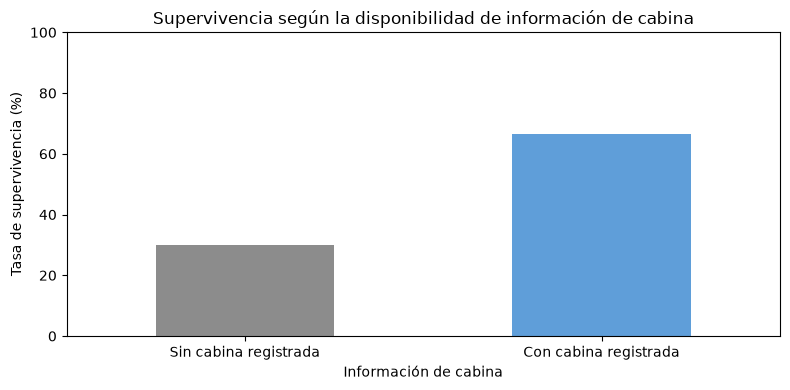

Survived,0,1
Has_Cabin,,
0,481,206
1,68,136


Chi-cuadrado: 87.94
P-valor: 6.7420e-21
Grados de libertad: 1
Existe una relación estadísticamente significativa entre tener información de cabina y la supervivencia.


In [148]:
# Creamos una copia para no modificar el DataFrame original
df_cabina = df.copy()

# Indicamos si existe información de cabina
df_cabina["Has_Cabin"] = df_cabina["Cabin"].notna().astype(int)

# Etiquetas comprensibles para el gráfico
df_cabina["Cabina_registrada"] = df_cabina["Has_Cabin"].map({
    0: "Sin cabina registrada",
    1: "Con cabina registrada"
})

# Calculamos las tasas de supervivencia
tasas_cabina = (
    df_cabina.groupby("Cabina_registrada")["Survived"]
             .agg(
                 Pasajeros="count",
                 Supervivientes="sum",
                 Tasa_supervivencia="mean"
             )
)

orden_cabina = [
    "Sin cabina registrada",
    "Con cabina registrada"
]

tasas_cabina = tasas_cabina.reindex(orden_cabina)
tasas_cabina["Tasa_supervivencia"] *= 100

display(tasas_cabina.round(2))

# Gráfico
tasas_cabina["Tasa_supervivencia"].plot(
    kind="bar",
    figsize=(8, 4),
    color=["#8c8c8c", "#5f9ed9"]
)

plt.title("Supervivencia según la disponibilidad de información de cabina")
plt.xlabel("Información de cabina")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Tabla de contingencia
tabla_cabina = pd.crosstab(
    df_cabina["Has_Cabin"],
    df_cabina["Survived"]
)

display(tabla_cabina)

# Prueba chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = (
    chi2_contingency(tabla_cabina)
)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")

if p_valor < 0.05:
    print(
        "Existe una relación estadísticamente significativa "
        "entre tener información de cabina y la supervivencia."
    )
else:
    print(
        "No se ha encontrado una relación estadísticamente "
        "significativa."
    )

Conclusión: Los pasajeros con información de cabina registrada tuvieron una tasa de supervivencia del 66,67 %, frente al 29,99 % de quienes no tenían ese dato. La prueba chi-cuadrado produjo un p-valor de aproximadamente 6,74 × 10⁻²¹, inferior a 0,05. Existe una relación estadísticamente significativa entre disponer de información de cabina y la supervivencia. Los resultados apoyan la hipótesis planteada. Sin embargo, un valor ausente no demuestra que el pasajero careciera de cabina, y esta variable puede actuar como indicador indirecto de la clase del billete.

8. **Hipótesis de Título**: Los pasajeros con ciertos títulos, como `Mrs`, `Miss` o `Master` (niños), tuvieron mejores probabilidades de sobrevivir que otros, reflejando su estatus social o edad.

,Pasajeros,Supervivientes,Tasa_supervivencia
Title,,,
Mr,517,81,15.67
Mrs,126,100,79.37
Miss,185,130,70.27
Master,40,23,57.50
Rare,23,8,34.78


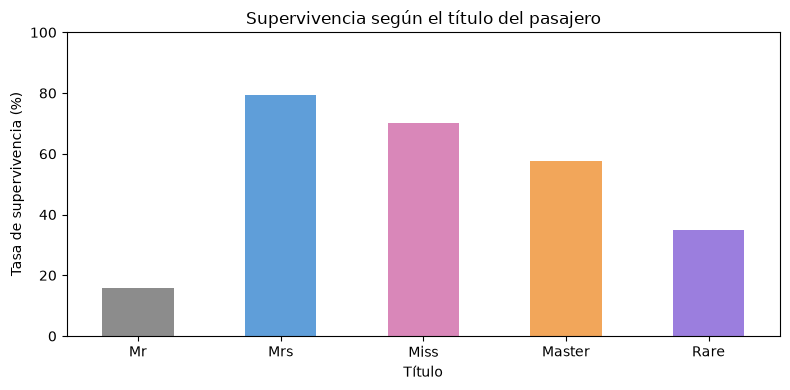

Survived,0,1
Title,,
Mr,436,81
Mrs,26,100
Miss,55,130
Master,17,23
Rare,15,8


Chi-cuadrado: 288.12
P-valor: 3.9579e-61
Grados de libertad: 4
Existe una relación estadísticamente significativa entre el título y la supervivencia.


In [149]:
# Creamos una copia para no modificar el DataFrame original
df_titulo = df.copy()

# Extraemos el título situado entre la coma y el punto del nombre
df_titulo["Title"] = (
    df_titulo["Name"]
    .str.extract(r",\s*([^\.]+)\.", expand=False)
    .str.strip()
)

# Unificamos títulos equivalentes
df_titulo["Title"] = df_titulo["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

# Agrupamos los títulos poco frecuentes
titulos_principales = ["Mr", "Mrs", "Miss", "Master"]

df_titulo.loc[
    ~df_titulo["Title"].isin(titulos_principales),
    "Title"
] = "Rare"

# Establecemos un orden para la tabla y el gráfico
orden_titulos = ["Mr", "Mrs", "Miss", "Master", "Rare"]

df_titulo["Title"] = pd.Categorical(
    df_titulo["Title"],
    categories=orden_titulos,
    ordered=True
)

# Calculamos las tasas de supervivencia
tasas_titulo = (
    df_titulo.groupby("Title", observed=False)["Survived"]
             .agg(
                 Pasajeros="count",
                 Supervivientes="sum",
                 Tasa_supervivencia="mean"
             )
)

tasas_titulo["Tasa_supervivencia"] *= 100
display(tasas_titulo.round(2))

# Gráfico
tasas_titulo["Tasa_supervivencia"].plot(
    kind="bar",
    figsize=(8, 4),
    color=["#8c8c8c", "#5f9ed9", "#d987b9", "#f2a65a", "#9b7ede"]
)

plt.title("Supervivencia según el título del pasajero")
plt.xlabel("Título")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Tabla de contingencia
tabla_titulo = pd.crosstab(
    df_titulo["Title"],
    df_titulo["Survived"]
)

display(tabla_titulo)

# Prueba chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = (
    chi2_contingency(tabla_titulo)
)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")

if p_valor < 0.05:
    print(
        "Existe una relación estadísticamente significativa "
        "entre el título y la supervivencia."
    )
else:
    print(
        "No se ha encontrado una relación estadísticamente "
        "significativa."
    )

Conclusión:Los títulos mostraron diferencias claras en las tasas de supervivencia. `Mrs` presentó la tasa más alta, con un 79,37 %, seguida de `Miss`, con un 70,27 %, y `Master`, con un 57,50 %. En cambio, los pasajeros con el título `Mr` tuvieron una tasa del 15,67 %. La prueba chi-cuadrado produjo un p-valor muy inferior a 0,05, por lo que existe una relación estadísticamente significativa entre el título y la supervivencia. Los resultados apoyan la hipótesis planteada. El título resume información relacionada con el sexo, la edad y la situación social, por lo que parte de su asociación con la supervivencia puede proceder de esas variables.

9. **Hipótesis del Número de Ticket**: Los pasajeros con números de ticket similares, lo que podría indicar que viajaban juntos, tuvieron probabilidades de supervivencia correlacionadas.

,Pasajeros,Supervivientes,Tasa_supervivencia
Tipo_ticket,,,
Individual,547,163,29.80
Compartido,344,179,52.03


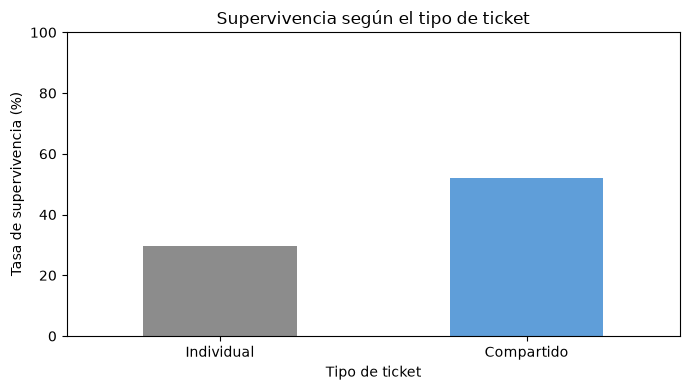

Survived,0,1
Tipo_ticket,,
Compartido,165,179
Individual,384,163


Chi-cuadrado: 43.22
P-valor: 4.9030e-11
Grados de libertad: 1
Existe una relación estadísticamente significativa entre compartir ticket y la supervivencia.
Grupos con ticket compartido: 134
Grupos con el mismo resultado: 85
Grupos con resultados diferentes: 49
Porcentaje de grupos uniformes: 63.43%


In [150]:
# Creamos una copia para no modificar el DataFrame original
df_ticket = df.copy()

# Contamos cuántos pasajeros tienen cada número de ticket
frecuencia_ticket = df_ticket["Ticket"].value_counts()

df_ticket["TicketGroupSize"] = (
    df_ticket["Ticket"].map(frecuencia_ticket)
)

# Clasificamos los tickets como individuales o compartidos
df_ticket["Tipo_ticket"] = np.where(
    df_ticket["TicketGroupSize"] > 1,
    "Compartido",
    "Individual"
)

# Calculamos las tasas de supervivencia
tasas_ticket = (
    df_ticket.groupby("Tipo_ticket")["Survived"]
             .agg(
                 Pasajeros="count",
                 Supervivientes="sum",
                 Tasa_supervivencia="mean"
             )
)

tasas_ticket = tasas_ticket.reindex([
    "Individual",
    "Compartido"
])

tasas_ticket["Tasa_supervivencia"] *= 100
display(tasas_ticket.round(2))

# Gráfico
tasas_ticket["Tasa_supervivencia"].plot(
    kind="bar",
    figsize=(7, 4),
    color=["#8c8c8c", "#5f9ed9"]
)

plt.title("Supervivencia según el tipo de ticket")
plt.xlabel("Tipo de ticket")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Tabla de contingencia
tabla_ticket = pd.crosstab(
    df_ticket["Tipo_ticket"],
    df_ticket["Survived"]
)

display(tabla_ticket)

# Prueba chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = (
    chi2_contingency(tabla_ticket)
)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"P-valor: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")

if p_valor < 0.05:
    print(
        "Existe una relación estadísticamente significativa "
        "entre compartir ticket y la supervivencia."
    )
else:
    print(
        "No se ha encontrado una relación estadísticamente "
        "significativa."
    )

# Analizamos si los pasajeros con el mismo ticket tuvieron resultados iguales
grupos_ticket = (
    df_ticket.groupby("Ticket")["Survived"]
             .agg(
                 Pasajeros="size",
                 Resultados_distintos="nunique"
             )
)

# Conservamos únicamente los tickets compartidos
grupos_compartidos = grupos_ticket[
    grupos_ticket["Pasajeros"] > 1
]

grupos_uniformes = (
    grupos_compartidos["Resultados_distintos"] == 1
).sum()

grupos_mixtos = (
    grupos_compartidos["Resultados_distintos"] > 1
).sum()

porcentaje_uniformes = (
    grupos_uniformes / len(grupos_compartidos) * 100
)

print(f"Grupos con ticket compartido: {len(grupos_compartidos)}")
print(f"Grupos con el mismo resultado: {grupos_uniformes}")
print(f"Grupos con resultados diferentes: {grupos_mixtos}")
print(f"Porcentaje de grupos uniformes: {porcentaje_uniformes:.2f}%")

Conclusión:Los pasajeros con un ticket compartido tuvieron una tasa de supervivencia del 52,03 %, frente al 29,80 % de quienes tenían un ticket individual. La prueba chi-cuadrado produjo un p-valor de aproximadamente 4,90 × 10⁻¹¹, inferior a 0,05, por lo que existe una relación estadísticamente significativa entre compartir ticket y la supervivencia. Además, 85 de los 134 grupos con ticket compartido, un 63,43 %, tuvieron el mismo resultado de supervivencia para todos sus integrantes. Los resultados apoyan la hipótesis de que los pasajeros que viajaban juntos presentaron resultados relacionados. Compartir ticket también puede estar asociado con la familia, la clase y la ubicación del grupo dentro del barco.

10. **Hipótesis de Interacciones**:
    - **Género y Clase**: Las mujeres de clases más altas tuvieron la mayor tasa de supervivencia.
    - **Edad y Clase**: Los niños de clases más bajas tuvieron menos probabilidades de sobrevivir que los niños de clases más altas.
    - **Tamaño de Familia y Tarifa**: Los pasajeros con familias más pequeñas y tarifas más altas tuvieron mayores probabilidades de supervivencia.

Sex,female,male
Pclass,,
1,96.81,36.89
2,92.11,15.74
3,50.00,13.54


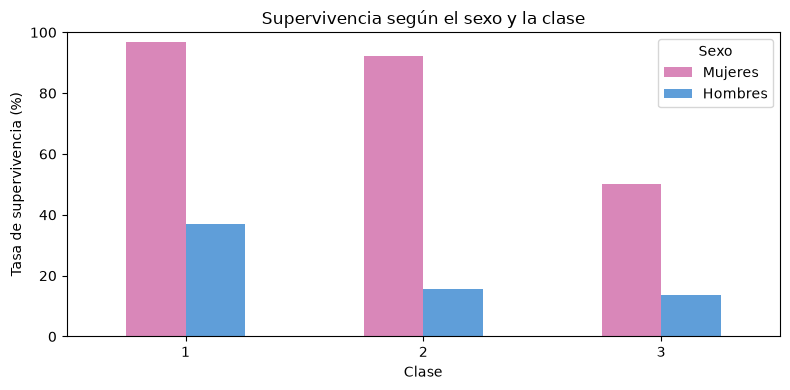

INTERACCIÓN SEXO Y CLASE
Chi-cuadrado: 350.68
P-valor: 1.2523e-73



Grupo_edad,Adulto,Menor de 18
Pclass,,
1,63.79,91.67
2,41.33,91.30
3,20.22,37.18


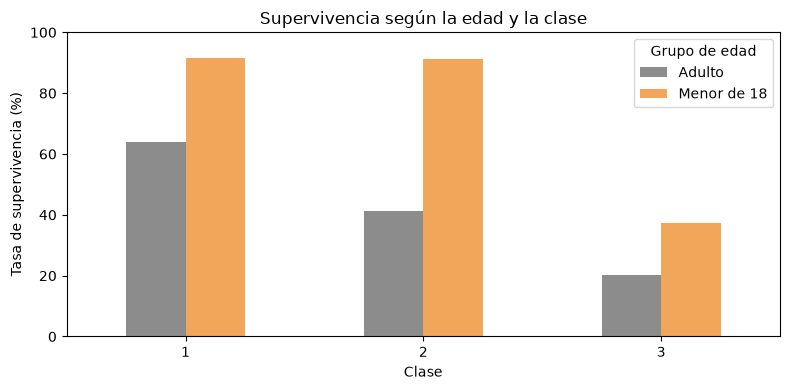

INTERACCIÓN EDAD Y CLASE
Chi-cuadrado: 124.42
P-valor: 3.6239e-25



Grupo_tarifa,Tarifa baja,Tarifa alta
Grupo_familia,,
Solo,23.68,49.29
Familia de 2 a 4,34.69,62.55
Familia de 5 o más,100.00,14.75


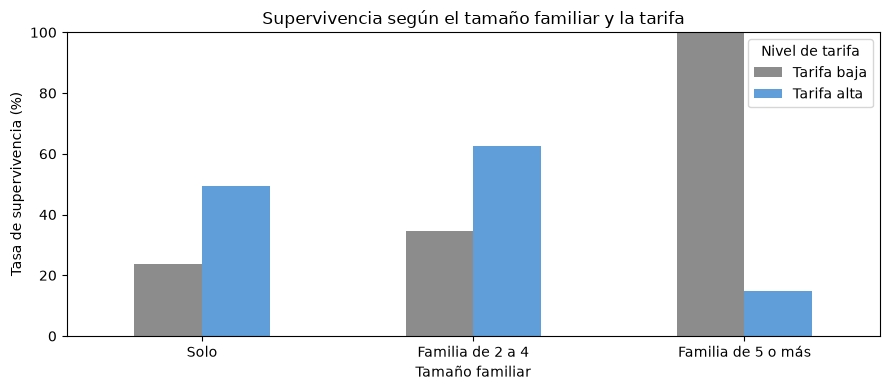

Mediana utilizada para dividir las tarifas: 14.45


,Pasajeros,Supervivientes,Tasa_supervivencia
Perfil_familia_tarifa,,,
Familia de 2 a 4 y tarifa alta,243,152,62.55
Resto de pasajeros,648,190,29.32


INTERACCIÓN TAMAÑO FAMILIAR Y TARIFA
Chi-cuadrado: 81.12
P-valor: 2.1285e-19

Las tres combinaciones presentan relaciones estadísticamente significativas con la supervivencia.


In [151]:
# Creamos una copia para no modificar el DataFrame original
df_interacciones = df.copy()

# ============================================================
# 1. INTERACCIÓN ENTRE SEXO Y CLASE
# ============================================================

tabla_sexo_clase = (
    df_interacciones.pivot_table(
        index="Pclass",
        columns="Sex",
        values="Survived",
        aggfunc="mean"
    ) * 100
)

display(tabla_sexo_clase.round(2))

tabla_sexo_clase.plot(
    kind="bar",
    figsize=(8, 4),
    color=["#d987b9", "#5f9ed9"]
)

plt.title("Supervivencia según el sexo y la clase")
plt.xlabel("Clase")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(["Mujeres", "Hombres"], title="Sexo")
plt.tight_layout()
plt.show()

# Creamos una categoría combinada para aplicar chi-cuadrado
df_interacciones["Sexo_Clase"] = (
    df_interacciones["Sex"].astype(str) +
    "_clase_" +
    df_interacciones["Pclass"].astype(str)
)

contingencia_sexo_clase = pd.crosstab(
    df_interacciones["Sexo_Clase"],
    df_interacciones["Survived"]
)

chi2_sc, p_sc, gl_sc, esperadas_sc = chi2_contingency(
    contingencia_sexo_clase
)

print("INTERACCIÓN SEXO Y CLASE")
print(f"Chi-cuadrado: {chi2_sc:.2f}")
print(f"P-valor: {p_sc:.4e}")
print()


# ============================================================
# 2. INTERACCIÓN ENTRE EDAD Y CLASE
# ============================================================

# Eliminamos solo los registros sin edad para este análisis
df_edad_clase = df_interacciones.dropna(subset=["Age"]).copy()

df_edad_clase["Grupo_edad"] = np.where(
    df_edad_clase["Age"] < 18,
    "Menor de 18",
    "Adulto"
)

tabla_edad_clase = (
    df_edad_clase.pivot_table(
        index="Pclass",
        columns="Grupo_edad",
        values="Survived",
        aggfunc="mean"
    ) * 100
)

tabla_edad_clase = tabla_edad_clase.reindex(
    columns=["Adulto", "Menor de 18"]
)

display(tabla_edad_clase.round(2))

tabla_edad_clase.plot(
    kind="bar",
    figsize=(8, 4),
    color=["#8c8c8c", "#f2a65a"]
)

plt.title("Supervivencia según la edad y la clase")
plt.xlabel("Clase")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Grupo de edad")
plt.tight_layout()
plt.show()

# Categoría combinada para chi-cuadrado
df_edad_clase["Edad_Clase"] = (
    df_edad_clase["Grupo_edad"].astype(str) +
    "_clase_" +
    df_edad_clase["Pclass"].astype(str)
)

contingencia_edad_clase = pd.crosstab(
    df_edad_clase["Edad_Clase"],
    df_edad_clase["Survived"]
)

chi2_ec, p_ec, gl_ec, esperadas_ec = chi2_contingency(
    contingencia_edad_clase
)

print("INTERACCIÓN EDAD Y CLASE")
print(f"Chi-cuadrado: {chi2_ec:.2f}")
print(f"P-valor: {p_ec:.4e}")
print()


# ============================================================
# 3. INTERACCIÓN ENTRE TAMAÑO FAMILIAR Y TARIFA
# ============================================================

df_interacciones["FamilySize"] = (
    df_interacciones["SibSp"] +
    df_interacciones["Parch"] +
    1
)

df_interacciones["Grupo_familia"] = pd.cut(
    df_interacciones["FamilySize"],
    bins=[0, 1, 4, np.inf],
    labels=[
        "Solo",
        "Familia de 2 a 4",
        "Familia de 5 o más"
    ]
)

# Dividimos las tarifas utilizando la mediana
mediana_tarifa = df_interacciones["Fare"].median()

df_interacciones["Grupo_tarifa"] = np.where(
    df_interacciones["Fare"] > mediana_tarifa,
    "Tarifa alta",
    "Tarifa baja"
)

tabla_familia_tarifa = (
    df_interacciones.pivot_table(
        index="Grupo_familia",
        columns="Grupo_tarifa",
        values="Survived",
        aggfunc="mean",
        observed=False
    ) * 100
)

tabla_familia_tarifa = tabla_familia_tarifa.reindex(
    columns=["Tarifa baja", "Tarifa alta"]
)

display(tabla_familia_tarifa.round(2))

tabla_familia_tarifa.plot(
    kind="bar",
    figsize=(9, 4),
    color=["#8c8c8c", "#5f9ed9"]
)

plt.title("Supervivencia según el tamaño familiar y la tarifa")
plt.xlabel("Tamaño familiar")
plt.ylabel("Tasa de supervivencia (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Nivel de tarifa")
plt.tight_layout()
plt.show()

print(f"Mediana utilizada para dividir las tarifas: {mediana_tarifa:.2f}")

# Perfil que representa la combinación planteada en la hipótesis
df_interacciones["Perfil_familia_tarifa"] = np.where(
    df_interacciones["FamilySize"].between(2, 4) &
    (df_interacciones["Fare"] > mediana_tarifa),
    "Familia de 2 a 4 y tarifa alta",
    "Resto de pasajeros"
)

tasas_perfil = (
    df_interacciones.groupby("Perfil_familia_tarifa")["Survived"]
                    .agg(
                        Pasajeros="count",
                        Supervivientes="sum",
                        Tasa_supervivencia="mean"
                    )
)

tasas_perfil["Tasa_supervivencia"] *= 100
display(tasas_perfil.round(2))

contingencia_familia_tarifa = pd.crosstab(
    df_interacciones["Perfil_familia_tarifa"],
    df_interacciones["Survived"]
)

chi2_ft, p_ft, gl_ft, esperadas_ft = chi2_contingency(
    contingencia_familia_tarifa
)

print("INTERACCIÓN TAMAÑO FAMILIAR Y TARIFA")
print(f"Chi-cuadrado: {chi2_ft:.2f}")
print(f"P-valor: {p_ft:.4e}")
print()

# Resultado general
if p_sc < 0.05 and p_ec < 0.05 and p_ft < 0.05:
    print(
        "Las tres combinaciones presentan relaciones "
        "estadísticamente significativas con la supervivencia."
    )
else:
    print(
        "Al menos una de las combinaciones no presenta "
        "una relación estadísticamente significativa."
    )

Conclusión: El análisis muestra que la supervivencia estuvo relacionada con distintas combinaciones de características. Las mujeres de primera clase presentaron la tasa más alta, con un 96,81 %, mientras que los hombres de tercera clase tuvieron una tasa del 13,54 %. La clase también influyó entre los menores: sobrevivió más del 91 % de los menores de primera y segunda clase, frente al 37,18 % de los menores de tercera clase. Los pasajeros que viajaban en familias de 2 a 4 personas y pagaron una tarifa superior a la mediana tuvieron una tasa de supervivencia del 62,55 %, frente al 29,32 % del resto. Las tres pruebas chi-cuadrado produjeron p-valores inferiores a 0,05. Los resultados apoyan las hipótesis de interacción entre sexo y clase, edad y clase, y tamaño familiar y tarifa. Estas asociaciones no permiten determinar por sí solas qué variable fue la causa directa de la supervivencia.

## Conclusiones

In [ ]:
## Conclusiones finales

El análisis muestra que la supervivencia de los pasajeros del Titanic no se distribuyó de manera uniforme. Las variables con una relación más clara fueron el sexo, la clase del billete y el título extraído del nombre. Las mujeres tuvieron una tasa de supervivencia del 74,20 %, frente al 18,89 % de los hombres. También se observó una fuerte diferencia por clase: sobrevivió el 62,96 % de los pasajeros de primera clase, frente al 24,24 % de los pasajeros de tercera.

La edad también estuvo relacionada con la supervivencia. Los menores de 18 años presentaron una tasa del 53,98 %, superior al 38,10 % de los adultos. Esta ventaja dependió de la clase: más del 91 % de los menores de primera y segunda clase sobrevivieron, mientras que en tercera clase la tasa fue del 37,18 %.

El tamaño familiar mostró una relación no lineal. Los pasajeros que viajaban en familias de 2 a 4 personas alcanzaron una tasa de supervivencia del 57,88 %. La tasa descendió al 30,35 % entre quienes viajaban solos y al 16,13 % en familias de 5 o más personas. Además, las familias de 2 a 4 miembros que pagaron una tarifa superior a la mediana alcanzaron una tasa del 62,55 %.

Los supervivientes pagaron tarifas más altas: su tarifa media fue de 48,40, frente a 22,12 entre quienes no sobrevivieron. También tuvieron mayor supervivencia los pasajeros que embarcaron en Cherburgo, quienes disponían de información de cabina y quienes compartían ticket. Estas relaciones pueden estar vinculadas con la clase socioeconómica y la ubicación dentro del barco.

El título extraído del nombre resultó especialmente informativo. Las tasas de `Mrs`, `Miss` y `Master` fueron muy superiores a la de `Mr`. Esta variable concentra información relacionada con el sexo, la edad y la situación social del pasajero.

Las pruebas estadísticas produjeron p-valores inferiores a 0,05 en las hipótesis analizadas. Los datos respaldan las relaciones planteadas, aunque no permiten afirmar que estas variables fueran causas directas de la supervivencia. Algunas están relacionadas entre sí; por ejemplo, la tarifa, la cabina y el puerto de embarque también dependen parcialmente de la clase.

El conjunto de datos contiene valores ausentes en `Age`, `Cabin` y `Embarked`. Será necesario tratarlos durante el preprocesamiento. Para construir el modelo predictivo, las variables más útiles serán `Sex`, `Pclass`, `Age`, `Fare`, `Embarked`, el tamaño familiar, la disponibilidad de información de cabina y el título extraído del nombre.